In [5]:
import numpy as np
import pandas as pd
import os
from matplotlib import pyplot as plt
from scipy.fft import fft, fftfreq
from scipy import signal
import os
from os import listdir
from os.path import isfile, join
import re
import MasterPSD as PSD
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
import glob
%matplotlib inline
param_map = {
    '5ms': {'time': 5},
    '50ms': {'time': 0.5},
    '500ms': {'time': 0.1},
    '5gs': {'time': 0.01},
    '250ks': {'time': 20}
}

In [7]:
import os
from os import PathLike
from pathlib import Path
import numpy as np
from datetime import time
from typing import Union, List, Dict, Any

# --- Helpers ---------------------------------------------------------------

def _parse_time_string(tstr: str) -> time:
    """Parse 'HH:MM:SS:ffffff' into a datetime.time."""
    h, m, s, us = tstr.split(':')
    return time(int(h), int(m), int(s), int(us))

def _time_to_seconds(t: time) -> float:
    return t.hour * 3600 + t.minute * 60 + t.second + t.microsecond / 1e6

def _measurement_key_from_ts(ts_array: np.ndarray) -> float:
    """Use the earliest timestamp in this measurement as its sort key."""
    if ts_array.size == 0:
        return float('inf')
    first_t = _parse_time_string(str(ts_array[0]))
    return _time_to_seconds(first_t)

# --- Core ------------------------------------------------------------------

def import_all_measurements(directory: Union[str, PathLike]) -> List[Dict[str, Any]]:
    """
    Scan `directory` for files that end with 'xs.npy', 'ts.npy', 'ns.npy'.
    Group by the shared prefix and return a list of dicts
    {'name','ts','ns','xs'} sorted by earliest timestamp in 'ts'.
    """
    directory = Path(directory)
    if not directory.is_dir():
        raise NotADirectoryError(f"{directory} is not a directory")

    found = {}
    for p in directory.glob("*.npy"):
        fn = p.name
        for suf in ("xs.npy", "ts.npy", "ns.npy"):
            if fn.endswith(suf):
                base = fn[:-len(suf)]
                found.setdefault(base, set()).add(suf)
                break

    complete_bases = [b for b, sset in found.items() if {"xs.npy", "ts.npy", "ns.npy"} <= sset]
    measurements: List[Dict[str, Any]] = []

    for base in complete_bases:
        xs = np.load(directory / f"{base}xs.npy", allow_pickle=False)
        ts = np.load(directory / f"{base}ts.npy", allow_pickle=False)
        ns = np.load(directory / f"{base}ns.npy", allow_pickle=False)

        if ts.dtype.kind not in ('U', 'S'):
            ts = ts.astype(str)

        measurements.append({"name": base, "ts": ts, "ns": ns, "xs": xs})

    measurements.sort(key=lambda rec: _measurement_key_from_ts(rec["ts"]))
    return measurements

def import_all_measurements_as_array(directory: Union[str, PathLike]) -> np.ndarray:
    """
    Same as import_all_measurements, but returns a numpy object array of tuples:
    (name, ts, ns, xs)
    """
    lst = import_all_measurements(directory)
    return np.array([(d["name"], d["ts"], d["ns"], d["xs"]) for d in lst], dtype=object)


In [9]:
meas_arr3 = import_all_measurements_as_array(r'D:\PhD Thesis Writing\Data\2025-11-18\IdqubeGates\nointerferometer\1mhz')

In [11]:
xs,ys=meas_arr3[0][2]/500,meas_arr3[0][3]
plt.plot(xs,ys)

IndexError: index 0 is out of bounds for axis 0 with size 0

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

# -------------------- Helpers --------------------

def parse_vtd_seconds(vtd):
    """Parse 'HH:MM:SS:ffffff' array to seconds since the first timestamp."""
    parsed = np.array([list(map(int, s.split(':'))) for s in vtd], dtype=np.int64)
    H, M, S, us = parsed.T
    t_us = ((H * 3600 + M * 60 + S) * 1_000_000 + us)
    # handle midnight wrap-around
    wraps = np.where(np.diff(t_us) < 0)[0]
    if wraps.size:
        day_us = 24 * 3600 * 1_000_000
        for w in wraps:
            t_us[w+1:] += day_us
    return (t_us - t_us[0]) / 1e6  # seconds

def centers_to_edges(t_center):
    """Make bin edges from bin centers by midpoints + symmetric extrapolation."""
    t_center = np.asarray(t_center, float)
    if t_center.size < 2:
        raise ValueError("Need at least two centers to infer edges.")
    mids = 0.5 * (t_center[:-1] + t_center[1:])
    first_edge = t_center[0] - (mids[0] - t_center[0])
    last_edge  = t_center[-1] + (t_center[-1] - mids[-1])
    return np.concatenate(([first_edge], mids, [last_edge]))

def poisson_constant_rate_test(dt, counts, make_plots=True):
    """
    Variable-width bins: counts_i ~ Poisson(mu_i = r * dt_i), constant r (Hz).
    Returns a dict of results and (optionally) plots standardized residuals.
    """
    dt = np.asarray(dt, float)
    y  = np.asarray(counts, float)
    if dt.shape != y.shape:
        raise ValueError("dt and counts must have the same shape.")
    if np.any(dt <= 0):
        raise ValueError("All bin widths (dt) must be > 0.")

    T = dt.sum()                # total exposure (s)
    N = y.sum()                 # total counts
    r_hat = N / T               # MLE rate (Hz)
    mu = r_hat * dt             # expected per bin

    # Pearson chi-square
    valid = mu > 0
    X2 = np.sum((y[valid] - mu[valid])**2 / mu[valid])
    df = max(1, int(valid.sum()) - 1)             # 1 fitted parameter (r)
    p_pearson = 1 - chi2.cdf(X2, df)
    dispersion_pearson = X2 / df                  # =1 for ideal Poisson

    # Poisson deviance (with 0*log(0/μ)=0 convention)
    c = y[valid]; m = mu[valid]
    D = 2 * np.sum(np.where(c > 0, c * np.log(c / m) - (c - m), m))
    p_deviance = 1 - chi2.cdf(D, df)
    dispersion_deviance = D / df

    # Exact 95% CI for r from N ~ Poisson(r*T): chi-square limits
    # r_low  = 0.5 * χ²_{α/2, 2N}   / T
    # r_high = 0.5 * χ²_{1-α/2, 2(N+1)} / T
    alpha = 0.05
    r_lo = (0.5 * chi2.ppf(alpha/2, df=2*int(N))) / T if N > 0 else 0.0
    r_hi = (0.5 * chi2.ppf(1 - alpha/2, df=2*int(N + 1))) / T

    # Standardized (Pearson) residuals
    resid = (y - mu) / np.sqrt(np.maximum(mu, 1e-12))

    print(f"Total exposure T = {T:.3f} s, total counts N = {N:.0f}")
    print(f"r_hat = {r_hat:.3f} Hz  (95% CI [{r_lo:.3f}, {r_hi:.3f}])")
    print(f"Pearson:  χ² = {X2:.2f}, df = {df}, p = {p_pearson:.3g},  χ²/df = {dispersion_pearson:.3f}")
    print(f"Deviance: D  = {D:.2f}, df = {df}, p = {p_deviance:.3g},  D/df  = {dispersion_deviance:.3f}")

    if make_plots:
        # residuals vs time (or index if you prefer)
        tmid = np.cumsum(dt) - 0.5*dt
        plt.figure(figsize=(10,3.5))
        plt.plot(tmid, resid, '.', ms=2)
        plt.axhline(0, linewidth=1)
        plt.xlabel('Time [s]')
        plt.ylabel('Pearson residual')
        plt.title('Residuals under constant-rate Poisson (variable exposures)')
        plt.grid(True, axis='y')
        plt.tight_layout()
        plt.show()

        # quick QQ-style discrete check (against N(0,1) as a rough guide)
        rs = np.sort(resid[np.isfinite(resid)])
        q = np.linspace(0.5/len(rs), 1-0.5/len(rs), len(rs))
        from scipy.stats import norm
        plt.figure(figsize=(4,4))
        plt.plot(norm.ppf(q), rs, '.', ms=2)
        mn = min(rs.min(), norm.ppf(q).min()); mx = max(rs.max(), norm.ppf(q).max())
        plt.plot([mn, mx], [mn, mx], '-', lw=1)
        plt.xlabel('Theoretical N(0,1) quantiles')
        plt.ylabel('Pearson residuals')
        plt.title('QQ plot (rough)')
        plt.tight_layout()
        plt.show()

    return {
        "r_hat_Hz": r_hat,
        "r_CI95": (r_lo, r_hi),
        "pearson_chi2": X2,
        "pearson_df": df,
        "pearson_p": p_pearson,
        "pearson_dispersion": dispersion_pearson,
        "deviance": D,
        "deviance_df": df,
        "deviance_p": p_deviance,
        "deviance_dispersion": dispersion_deviance,
        "residuals": resid,
        "mu": mu,
    }

# -------------------- How to call --------------------
# If you have timestamp *centers* (strings like your vtd) and counts:
# t_centers = parse_vtd_seconds(vtd)
# edges = centers_to_edges(t_centers)
# dt = np.diff(edges)                 # exposures per variable bin
# results = poisson_constant_rate_test(dt, counts, make_plots=True)

# If you already have bin edges: dt = np.diff(edges) and call the test directly.


In [11]:
for i in range(len(meas_arr3[0][3])):
    if meas_arr3[0][3][i]>=70:
        meas_arr3[0][3][i]=55

In [13]:
vtd=meas_arr3[0][1]
counts=meas_arr3[0][3]

Total exposure T = 3433.871 s, total counts N = 63172236
r_hat = 18396.800 Hz  (95% CI [18392.264, 18401.337])
Pearson:  χ² = 1542739.10, df = 1768285, p = 1,  χ²/df = 0.872
Deviance: D  = 1526119.54, df = 1768285, p = 1,  D/df  = 0.863


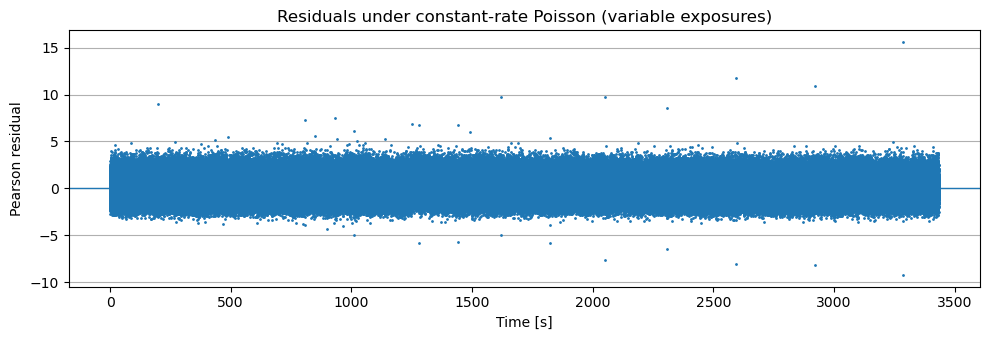

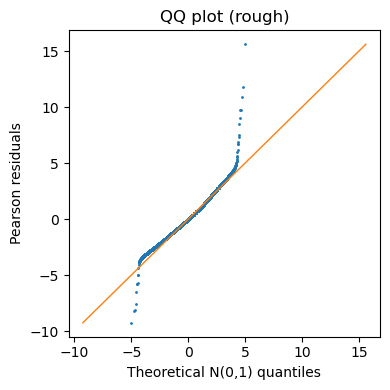

In [21]:
# If you have timestamp *centers* (strings like your vtd) and counts:
t_centers = parse_vtd_seconds(vtd)
edges = centers_to_edges(t_centers)
dt = np.diff(edges)                 # exposures per variable bin
results = poisson_constant_rate_test(dt, counts, make_plots=True)

# If you already have bin edges: dt = np.diff(edges) and call the test directly.


In [23]:
import numpy as np
from scipy.stats import chi2

dt = dt  # your exposures per bin (seconds)
y  = counts.astype(float)

T = dt.sum()
N = y.sum()
r_hat = N / T
mu = r_hat * dt

# Pearson dispersion
pearson = np.sum((y - mu)**2 / np.maximum(mu, 1e-12))
df = len(y) - 1
phi = pearson / df

# Exact Poisson CI (conservative for you)
alpha = 0.05
r_lo = 0.0 if N == 0 else (0.5 * chi2.ppf(alpha/2, df=2*int(N))) / T
r_hi = (0.5 * chi2.ppf(1 - alpha/2, df=2*int(N + 1))) / T

# Quasi-Poisson (under-dispersion-adjusted) Wald CI
se0 = np.sqrt(r_hat / T)
se_phi = np.sqrt(phi) * se0
r_lo_q = r_hat - 1.96 * se_phi
r_hi_q = r_hat + 1.96 * se_phi

print(f"r_hat = {r_hat:.3f} Hz")
print(f"Exact Poisson 95% CI: [{r_lo:.3f}, {r_hi:.3f}]")
print(f"Pearson dispersion φ = {phi:.3f}")
print(f"Quasi-Poisson 95% CI (φ): [{r_lo_q:.3f}, {r_hi_q:.3f}]")


r_hat = 18396.800 Hz
Exact Poisson 95% CI: [18392.264, 18401.337]
Pearson dispersion φ = 0.872
Quasi-Poisson 95% CI (φ): [18392.562, 18401.037]


In [25]:
import numpy as np
from scipy.stats import chi2

# ---------- Constant-rate Poisson fit (variable exposures) ----------
def fit_constant_rate(dt, counts):
    dt = np.asarray(dt, float)
    y  = np.asarray(counts, float)
    if dt.shape != y.shape:
        raise ValueError("dt and counts must have the same shape.")
    if np.any(dt <= 0):
        raise ValueError("All dt must be > 0.")
    T = dt.sum()
    N = y.sum()
    r_hat = N / T
    mu = r_hat * dt
    resid = (y - mu) / np.sqrt(np.maximum(mu, 1e-12))  # Pearson residuals
    # Pearson dispersion
    X2 = np.sum((y - mu)**2 / np.maximum(mu, 1e-12))
    df = len(y) - 1
    phi = X2 / df
    return dict(r_hat=r_hat, mu=mu, resid=resid, T=T, N=N, pearson_chi2=X2, df=df, dispersion=phi)

# ---------- Ljung–Box via statsmodels if available ----------
def ljung_box(resid, lags=20):
    """
    Returns (stat, pvalue) for given 'lags'.
    Uses statsmodels if available; falls back to a manual implementation otherwise.
    """
    try:
        from statsmodels.stats.diagnostic import acorr_ljungbox
        res = acorr_ljungbox(resid, lags=[lags], return_df=True)
        return float(res['lb_stat'].iloc[0]), float(res['lb_pvalue'].iloc[0])
    except Exception:
        # Manual Ljung–Box (asymptotic): Q = n(n+2) * sum_{k=1..h} r_k^2 / (n-k)
        x = np.asarray(resid, float)
        x = x[np.isfinite(x)]
        n = len(x)
        if n < lags + 1:
            raise ValueError("Series too short for requested lags.")
        x = x - x.mean()
        denom = np.sum(x**2)
        r = []
        for k in range(1, lags+1):
            r_k = np.dot(x[:-k], x[k:]) / denom
            r.append(r_k)
        r = np.array(r)
        Q = n*(n+2) * np.sum(r*r / (n - np.arange(1, lags+1)))
        p = 1 - chi2.cdf(Q, df=lags)
        return float(Q), float(p)

# ---------- Example usage ----------
# You already have: dt (seconds per bin), counts (per bin)
results = fit_constant_rate(dt, counts)
print(f"r_hat = {results['r_hat']:.3f} Hz, dispersion (Pearson/df) = {results['dispersion']:.3f}")
Q, p = ljung_box(results['resid'], lags=20)
print(f"Ljung–Box lag-20: Q={Q:.2f}, p={p:.3g}")


r_hat = 18396.800 Hz, dispersion (Pearson/df) = 0.872
Ljung–Box lag-20: Q=63796.80, p=0


In [29]:
import numpy as np
from scipy.stats import chi2

def coarsen_variable_bins(dt, counts, window_s=2.0, drop_last_partial=True):
    """
    Greedily accumulates consecutive (dt_i, y_i) into windows with total exposure >= window_s.
    Returns (DT, Y) where each row is a coarsened window: DT_j = sum dt_i, Y_j = sum y_i within window.
    If drop_last_partial=False, includes the last window even if exposure < window_s.
    """
    dt = np.asarray(dt, float)
    y  = np.asarray(counts, float)
    if dt.shape != y.shape:
        raise ValueError("dt and counts must have the same shape.")
    if np.any(dt <= 0):
        raise ValueError("All dt must be > 0.")

    DT, Y = [], []
    acc_t, acc_y = 0.0, 0.0
    for dti, yi in zip(dt, y):
        acc_t += dti
        acc_y += yi
        if acc_t >= window_s:
            DT.append(acc_t)
            Y.append(acc_y)
            acc_t, acc_y = 0.0, 0.0

    if (not drop_last_partial) and acc_t > 0:
        DT.append(acc_t)
        Y.append(acc_y)

    return np.array(DT, float), np.array(Y, float)

def poisson_constant_rate_test(dt, counts):
    """
    Same constant-rate Poisson GOF as in Script A, summarized nicely.
    """
    dt = np.asarray(dt, float)
    y  = np.asarray(counts, float)
    T = dt.sum()
    N = y.sum()
    r_hat = N / T
    mu = r_hat * dt

    valid = mu > 0
    X2 = np.sum((y[valid] - mu[valid])**2 / mu[valid])
    D  = 2 * np.sum(np.where(y[valid] > 0,
                             y[valid]*np.log(y[valid]/mu[valid]) - (y[valid]-mu[valid]),
                             mu[valid]))
    df = int(valid.sum()) - 1
    p_pear = 1 - chi2.cdf(X2, df)
    p_dev  = 1 - chi2.cdf(D,  df)
    return dict(r_hat=r_hat, T=T, N=N, pearson_chi2=X2, deviance=D, df=df,
                pearson_over_df=X2/df, deviance_over_df=D/df,
                p_pearson=p_pear, p_deviance=p_dev)

# ---------- Example usage ----------
# 1) Start from your fine bins (variable dt, counts)
W = 2.0  # seconds; choose >= the smoothing/overlap span you diagnosed
DT2, Y2 = coarsen_variable_bins(dt, counts, window_s=W, drop_last_partial=True)
print(f"Coarsened into {len(Y2)} windows of >= {W}s; total exposure {DT2.sum():.2f}s")

# 2) Test constant-rate Poisson on the coarsened series
out = poisson_constant_rate_test(DT2, Y2)
print(f"r_hat={out['r_hat']:.3f} Hz, Pearson/df={out['pearson_over_df']:.3f}, Deviance/df={out['deviance_over_df']:.3f}")
print(f"Pearson: χ²={out['pearson_chi2']:.1f}, df={out['df']}, p={out['p_pearson']:.3g}")
print(f"Deviance: D={out['deviance']:.1f}, df={out['df']}, p={out['p_deviance']:.3g}")

# 3) (Optional) Now do Ljung–Box on the coarsened Pearson residuals
r = out['r_hat']; mu2 = r * DT2
resid2 = (Y2 - mu2) / np.sqrt(np.maximum(mu2, 1e-12))
Q2, p2 = ljung_box(resid2, lags=10)
print(f"Ljung–Box on coarsened residuals (lag=10): Q={Q2:.1f}, p={p2:.3g}")


Coarsened into 1716 windows of >= 2.0s; total exposure 3433.79s
r_hat=18396.786 Hz, Pearson/df=5.393, Deviance/df=5.387
Pearson: χ²=9248.3, df=1715, p=0
Deviance: D=9239.2, df=1715, p=0
Ljung–Box on coarsened residuals (lag=10): Q=4977.7, p=0


In [33]:
import numpy as np
from scipy.stats import chi2

def ljung_box_fast(resid, lags=20):
    """
    Fast Ljung–Box Q-test using an FFT-based autocorrelation.
    Works even for very long series. Returns (Q, p, r[1:lags+1]).
    """
    x = np.asarray(resid, dtype=np.float64)
    x = x[np.isfinite(x)]
    n = x.size
    if n < lags + 1:
        raise ValueError(f"Series too short (n={n}) for lags={lags}.")

    # demean
    x -= x.mean()

    # FFT-based ACF up to 'lags'
    # zero-pad to next power of two for speed/stability
    nfft = 1 << (int((2*n - 1)).bit_length())
    Xf = np.fft.rfft(x, nfft)
    S  = Xf * np.conj(Xf)
    acf_full = np.fft.irfft(S, nfft)[:lags+1]
    acf_full /= acf_full[0]  # normalize by variance

    r = acf_full[1:lags+1]   # lags 1..h

    # Ljung–Box statistic: Q = n(n+2) * sum_{k=1}^h r_k^2 / (n-k)
    k = np.arange(1, lags+1, dtype=np.float64)
    Q = n*(n+2.0) * np.sum((r*r) / (n - k))
    p = 1.0 - chi2.cdf(Q, df=lags)
    return float(Q), float(p), r

# Example usage with your existing results dict
# results = fit_constant_rate(dt, counts)
Q, p, r = ljung_box_fast(results['resid'], lags=20)
print(f"Ljung–Box (lag=20): Q={Q:.2f}, p={p:.3g}")
print("ACF[1..20]:", np.round(r, 4))


Ljung–Box (lag=20): Q=63796.80, p=0
ACF[1..20]: [ 0.0298 -0.1723 -0.0236  0.0042  0.0323  0.0006 -0.0129 -0.0051 -0.0055
  0.0188  0.0142 -0.0041 -0.0144 -0.0121  0.0282  0.0376  0.0031 -0.0032
  0.0037  0.0221]


In [35]:
import numpy as np
import statsmodels.api as sm
from patsy import dmatrix
from scipy.stats import chi2

def fit_poisson_spline(y, t, dfs=(20, 40, 60, 80)):
    """
    y: counts per bin
    t: time midpoints (seconds) for each bin (same length)
    dfs: grid of spline dfs to try
    Returns: best result dict with model, residuals, dispersion, LB, etc.
    """
    best = None
    for df in dfs:
        X = dmatrix(f"bs(t, df={df}, degree=3, include_intercept=True)", {"t": t})
        mod = sm.GLM(y, X, family=sm.families.Poisson())
        res = mod.fit()
        dev = float(res.deviance)
        pearson = float(getattr(res, "pearson_chi2", np.nan))
        df_resid = int(res.df_resid)
        disp_dev = dev/df_resid
        disp_pear = pearson/df_resid
        # Ljung–Box on deviance residuals
        r_dev = np.asarray(res.resid_deviance, float)
        Q, p, _ = ljung_box_fast(r_dev, lags=20)
        cand = dict(df=df, model=res, AIC=res.aic, deviance=dev, pearson=pearson,
                    df_resid=df_resid, disp_dev=disp_dev, disp_pear=disp_pear,
                    lb_Q=Q, lb_p=p, resid=r_dev)
        if (best is None) or (cand["AIC"] < best["AIC"]):
            best = cand
    return best

# Build time midpoints for your variable-width bins
# (tmid is used only as the covariate for the smooth mean)
tmid = np.cumsum(dt) - 0.5*dt
y = counts.astype(float)

best = fit_poisson_spline(y, tmid, dfs=(20, 40, 60, 80, 100))
print(f"Best df={best['df']} | AIC={best['AIC']:.1f}")
print(f"Deviance/df={best['disp_dev']:.3f}  Pearson/df={best['disp_pear']:.3f}")
print(f"Ljung–Box on deviance residuals (lag=20): Q={best['lb_Q']:.1f}, p={best['lb_p']:.3g}")

# If desired, robust (sandwich) SEs to guard against remaining misspecification
robust = best["model"].get_robustcov_results(cov_type="HC0")
print(robust.summary())


C:\Users\Ry\anaconda3\lib\site-packages\statsmodels\genmod\families\links.py:527: RuntimeWarning: overflow encountered in exp
  return np.exp(z)
C:\Users\Ry\anaconda3\lib\site-packages\statsmodels\genmod\families\family.py:143: RuntimeWarning: invalid value encountered in multiply
  return 1. / (self.link.deriv(mu)**2 * self.variance(mu))
C:\Users\Ry\anaconda3\lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1243: RuntimeWarning: invalid value encountered in multiply
  wlsendog = (lin_pred + self.family.link.deriv(mu) * (self.endog-mu)


ValueError: NaN, inf or invalid value detected in weights, estimation infeasible.

In [39]:
import numpy as np
import statsmodels.api as sm
from patsy import dmatrix
from scipy.stats import chi2

def fit_poisson_spline_safe(counts, dt, dfs=(20, 40, 60, 80), lags=20, alpha_ridge=1e-4):
    """
    Poisson GLM with cubic regression splines and exposure offset log(dt).
    Robust to overflow/NaN via standardization and small L2-regularized fallback.

    Returns a dict with the best-AIC model and diagnostics.
    """
    y = np.asarray(counts, float)
    dt = np.asarray(dt, float)

    # ---- sanitize ----
    mask = np.isfinite(y) & np.isfinite(dt) & (dt > 0)
    if mask.sum() < len(y):
        y, dt = y[mask], dt[mask]
    if (y < 0).any():
        raise ValueError("Counts must be nonnegative.")
    if len(y) < 10:
        raise ValueError("Too few observations.")

    # time midpoints and scaling to [-0.5, 0.5]
    t = np.cumsum(dt) - 0.5 * dt
    tmin, tmax = t.min(), t.max()
    t_scaled = (t - tmin) / (tmax - tmin) - 0.5

    # log exposure offset
    off = np.log(dt)

    best = None
    for df in dfs:
        # build spline basis on scaled time; we add an explicit intercept
        X = dmatrix(f"bs(t, df={df}, degree=3, include_intercept=False)",
                    {"t": t_scaled}, return_type='dataframe')
        X = np.column_stack([np.ones(len(y)), np.asarray(X)])  # intercept + basis

        # helper to score model
        def score_fit(res):
            dev = float(res.deviance)
            pearson = float(getattr(res, "pearson_chi2", np.nan))
            df_resid = int(res.df_resid)
            disp_dev = dev / df_resid
            disp_pear = pearson / df_resid
            aic = float(res.aic)
            return dict(df=df, model=res, AIC=aic, deviance=dev, pearson=pearson,
                        df_resid=df_resid, disp_dev=disp_dev, disp_pear=disp_pear)

        # try standard IRLS first
        try:
            mod = sm.GLM(y, X, family=sm.families.Poisson(), offset=off)
            # good starting values: log-mean minus offset for intercept, zeros for splines
            eta0 = np.log(np.maximum(y.mean(), 1e-12)) - np.log(np.mean(dt))
            start = np.zeros(X.shape[1]); start[0] = eta0
            res = mod.fit(start_params=start, maxiter=100, atol=1e-8)
            cand = score_fit(res)
        except Exception:
            # fallback: small ridge (L2); penalty excludes intercept by scaling columns
            col_scale = np.ones(X.shape[1])
            col_scale[0] = 1e6  # effectively no penalty on intercept
            mod = sm.GLM(y, X / col_scale, family=sm.families.Poisson(), offset=off)
            res = mod.fit_regularized(alpha=alpha_ridge, L1_wt=0.0, maxiter=1000)
            # res.params are on scaled columns, unscale:
            res.params = res.params / col_scale
            # wrap params back into a GLMResults-like object for deviance/AIC via evaluate
            mu = np.exp(off + X @ res.params)
            # compute deviance & pearson manually
            with np.errstate(divide='ignore', invalid='ignore'):
                dev_terms = np.where(y > 0, y * np.log(y / mu) - (y - mu), - (0 - mu))
            dev = 2 * np.sum(np.where(y > 0, y * np.log(y / mu) - (y - mu), mu))
            pearson = np.sum((y - mu)**2 / np.maximum(mu, 1e-12))
            df_resid = len(y) - X.shape[1]
            aic = 2 * (X.shape[1]) - 2 * np.sum(y * np.log(mu) - mu)  # constant terms drop
            cand = dict(df=df, model=res, AIC=aic, deviance=dev, pearson=pearson,
                        df_resid=df_resid, disp_dev=dev/df_resid, disp_pear=pearson/df_resid)

        if (best is None) or (cand["AIC"] < best["AIC"]):
            best = cand

    # Ljung–Box on deviance residuals (fast FFT version)
    def ljung_box_fast(resid, lags=20):
        x = np.asarray(resid, float)
        x = x[np.isfinite(x)]
        n = x.size
        if n < lags + 1:
            return np.nan, np.nan
        x -= x.mean()
        nfft = 1 << (int((2*n - 1)).bit_length())
        Xf = np.fft.rfft(x, nfft); S = Xf * np.conj(Xf)
        acf = np.fft.irfft(S, nfft)[:lags+1]; acf /= acf[0]
        r = acf[1:lags+1]
        k = np.arange(1, lags+1, dtype=float)
        Q = n*(n+2.0)*np.sum((r*r)/(n-k))
        p = 1 - chi2.cdf(Q, df=lags)
        return float(Q), float(p)

    # compute deviance residuals from the (possibly regularized) fit
    # if we have GLMResults, use its resid_deviance; else compute from params
    try:
        r_dev = np.asarray(best["model"].resid_deviance, float)
    except Exception:
        params = best["model"].params
        mu = np.exp(off + X @ params)
        # deviance residuals
        with np.errstate(divide='ignore', invalid='ignore'):
            r_dev = np.sign(y - mu) * np.sqrt(2 * np.where(y > 0, y * np.log(y / mu) - (y - mu), mu))
    Q, p = ljung_box_fast(r_dev, lags=lags)
    best["lb_Q"] = Q
    best["lb_p"] = p
    best["resid_dev"] = r_dev
    best["t_scaled"] = t_scaled
    return best

# -------- How to call (replace your earlier call with this) --------
y = counts.astype(float)
dt = dt  # your per-bin exposures
out = fit_poisson_spline_safe(y, dt, dfs=(20, 40, 60, 80, 100), lags=20, alpha_ridge=1e-4)
print(f"Best df={out['df']} | AIC={out['AIC']:.1f}")
print(f"Deviance/df={out['disp_dev']:.3f}  Pearson/df={out['disp_pear']:.3f}")
print(f"Ljung–Box on deviance residuals (lag=20): Q={out['lb_Q']:.1f}, p={out['lb_p']:.3g}")


Best df=100 | AIC=11088484.8
Deviance/df=0.860  Pearson/df=0.869
Ljung–Box on deviance residuals (lag=20): Q=64934.6, p=0


In [45]:
import numpy as np
from scipy.stats import chi2

# ---------- 0) Parse your timestamp centers to seconds ----------
def parse_vtd_seconds(vtd):
    """Parse 'HH:MM:SS:ffffff' strings -> seconds since first sample."""
    vtd = np.asarray(vtd)
    parsed = np.array([list(map(int, s.split(':'))) for s in vtd], dtype=np.int64)
    H, M, S, us = parsed.T
    t_us = ((H * 3600 + M * 60 + S) * 1_000_000 + us)
    # handle midnight wrap
    wraps = np.where(np.diff(t_us) < 0)[0]
    if wraps.size:
        day_us = 24 * 3600 * 1_000_000
        for w in wraps:
            t_us[w+1:] += day_us
    return (t_us - t_us[0]) / 1e6

def centers_to_edges(t_center):
    """Infer bin edges from bin centers via midpoints + symmetric ends."""
    t_center = np.asarray(t_center, float)
    if t_center.size < 2:
        raise ValueError("Need at least two centers to infer edges.")
    mids = 0.5 * (t_center[:-1] + t_center[1:])
    first_edge = t_center[0] - (mids[0] - t_center[0])
    last_edge  = t_center[-1] + (t_center[-1] - mids[-1])
    return np.concatenate(([first_edge], mids, [last_edge]))

# ---------- 1) Core: constant-rate Poisson GOF on variable widths ----------
def poisson_constant_rate_test(dt, counts):
    """
    counts_i ~ Poisson(mu_i = r * dt_i), with a single r per segment.
    Returns dict with r_hat, CIs, Pearson/Deviance chi2, p-values, dispersion, residuals.
    """
    dt = np.asarray(dt, float)
    y  = np.asarray(counts, float)
    if dt.shape != y.shape:
        raise ValueError("dt and counts must have the same length.")
    if np.any(dt <= 0):
        raise ValueError("All dt must be > 0.")
    mask = np.isfinite(dt) & np.isfinite(y)
    dt, y = dt[mask], y[mask]

    T = dt.sum()                  # seconds exposure in this segment
    N = y.sum()
    r_hat = N / T                 # Hz
    mu = r_hat * dt

    valid = mu > 0
    # Pearson chi-square
    X2 = np.sum((y[valid] - mu[valid])**2 / mu[valid])
    df = max(1, int(valid.sum()) - 1)       # 1 fitted parameter (r)
    p_pear = 1 - chi2.cdf(X2, df)
    disp_pear = X2 / df

    # Deviance (0*log(0/mu)=0)
    c = y[valid]; m = mu[valid]
    D = 2 * np.sum(np.where(c > 0, c*np.log(c/m) - (c - m), m))
    p_dev = 1 - chi2.cdf(D, df)
    disp_dev = D / df

    # Exact 95% CI for r from N ~ Poisson(r*T)
    alpha = 0.05
    r_lo = (0.5 * chi2.ppf(alpha/2, df=2*int(N))) / T if N > 0 else 0.0
    r_hi = (0.5 * chi2.ppf(1 - alpha/2, df=2*int(N + 1))) / T

    resid = (y - mu) / np.sqrt(np.maximum(mu, 1e-12))

    return dict(
        T=T, N=N, r_hat=r_hat, r_CI95=(r_lo, r_hi),
        pearson_chi2=X2, pearson_df=df, pearson_p=p_pear, pearson_disp=disp_pear,
        deviance=D, deviance_df=df, deviance_p=p_dev, deviance_disp=disp_dev,
        resid=resid
    )

# ---------- 2) Segment the series into n equal-exposure segments ----------
def segment_by_exposure(dt, counts, n_segments):
    """
    Split sequential (dt, counts) into n contiguous segments of ~equal total exposure.
    Returns list of slices [(i0,i1), ...] where segment j is [i0:i1].
    """
    dt = np.asarray(dt, float); counts = np.asarray(counts)
    if dt.size != counts.size:
        raise ValueError("dt and counts must have the same length.")
    T = dt.sum()
    target = T / n_segments
    sl = []
    i0 = 0
    acc = 0.0
    for i in range(dt.size):
        acc += dt[i]
        if acc >= target and len(sl) < n_segments - 1:
            sl.append((i0, i+1))
            i0 = i+1
            acc = 0.0
    sl.append((i0, dt.size))
    return sl

# ---------- 3) Multiple-testing helper (Benjamini–Hochberg FDR) ----------
def bh_fdr(pvals, alpha=0.05):
    p = np.array(pvals, float)
    m = np.isfinite(p).sum()
    idx = np.argsort(p)
    thr = alpha * (np.arange(1, m+1) / m)
    passed = np.zeros_like(p, dtype=bool)
    if m:
        k = np.where(p[idx] <= thr)[0]
        if k.size:
            cutoff = p[idx[k[-1]]]
            passed = p <= cutoff
    return passed

# ---------- 4) Driver: from vtd + counts to per-segment Poisson check ----------
def segmentwise_poisson_test(vtd_centers, counts, n_segments=10, report='both'):
    """
    vtd_centers: array of timestamp centers (strings 'HH:MM:SS:ffffff')
    counts:      array of counts per center (same length)
    n_segments:  number of contiguous equal-exposure segments
    report:      'pearson' | 'deviance' | 'both'
    Returns: dict with per-segment results and FDR summaries.
    """
    t_center = parse_vtd_seconds(vtd_centers)
    edges = centers_to_edges(t_center)
    dt = np.diff(edges)

    # Build segments
    segs = segment_by_exposure(dt, counts, n_segments)

    results = []
    p_pear = []
    p_dev  = []
    for j, (i0, i1) in enumerate(segs, start=1):
        out = poisson_constant_rate_test(dt[i0:i1], counts[i0:i1])
        out['segment'] = j
        out['i0_i1'] = (i0, i1)
        out['t_start'] = edges[i0]
        out['t_end']   = edges[i1]
        results.append(out)
        p_pear.append(out['pearson_p'])
        p_dev.append(out['deviance_p'])

    # FDR across segments
    fdr = {}
    if report in ('pearson', 'both'):
        fdr['pearson_pass'] = bh_fdr(p_pear, alpha=0.05)
    if report in ('deviance', 'both'):
        fdr['deviance_pass'] = bh_fdr(p_dev, alpha=0.05)

    # Pretty print summary
    print(f"\nSegmented into {len(segs)} segments (equal exposure).")
    print("Seg |  t_start–t_end [s] |    r_hat [Hz]    CI95 low    CI95 high |  Pear χ2/df  p      |  Dev/df  p")
    print("-"*110)
    for j, out in enumerate(results, start=1):
        chi_over_df = out['pearson_chi2']/out['pearson_df']
        dev_over_df = out['deviance']/out['deviance_df']
        print(f"{j:>3d} | {out['t_start']:8.3f}–{out['t_end']:8.3f} | "
              f"{out['r_hat']:12.3f}  {out['r_CI95'][0]:10.3f}  {out['r_CI95'][1]:10.3f} | "
              f"{chi_over_df:7.3f}  {out['pearson_p']:.2g} | {dev_over_df:7.3f}  {out['deviance_p']:.2g}")

    # FDR results
    if fdr:
        print("\nBenjamini–Hochberg FDR (α=0.05):")
        if 'pearson_pass' in fdr:
            k = int(np.sum(fdr['pearson_pass']))
            print(f"  Pearson: {k}/{len(segs)} segments NOT rejected (fail to reject Poisson).")
        if 'deviance_pass' in fdr:
            k = int(np.sum(fdr['deviance_pass']))
            print(f"  Deviance: {k}/{len(segs)} segments NOT rejected (fail to reject Poisson).")

    return {"segments": segs, "results": results, "fdr": fdr}

In [63]:

# ---------------- Example call ----------------
n_segments = 2000
out = segmentwise_poisson_test(vtd, counts, n_segments=n_segments, report='both')


Segmented into 1999 segments (equal exposure).
Seg |  t_start–t_end [s] |    r_hat [Hz]    CI95 low    CI95 high |  Pear χ2/df  p      |  Dev/df  p
--------------------------------------------------------------------------------------------------------------
  1 |   -0.000–   1.718 |    18258.058   18056.566   18461.238 |   0.847  1 |   0.841  1
  2 |    1.718–   3.435 |    18390.890   18188.607   18594.863 |   0.815  1 |   0.806  1
  3 |    3.435–   5.153 |    18457.936   18255.318   18662.243 |   0.954  0.83 |   0.930  0.93
  4 |    5.153–   6.869 |    18470.624   18267.889   18675.049 |   0.856  1 |   0.853  1
  5 |    6.869–   8.588 |    18322.229   18120.401   18525.745 |   0.884  0.99 |   0.873  1
  6 |    8.588–  10.305 |    18061.937   17861.485   18264.078 |   0.923  0.95 |   0.919  0.96
  7 |   10.305–  12.023 |    17963.582   17763.729   18165.123 |   0.925  0.95 |   0.914  0.97
  8 |   12.023–  13.741 |    17901.579   17702.012   18102.834 |   0.991  0.57 |   0.975  0.69
 

In [57]:
ns = np.loadtxt(r'D:\PhD Thesis Writing\Data\2025-06-10\fiber_fiber_interferometer_fibrearm_postLP_noise_posttape_long.csv',skiprows=15, delimiter=',', usecols=0)
ps = np.loadtxt(r'D:\PhD Thesis Writing\Data\2025-06-10\fiber_fiber_interferometer_fibrearm_postLP_noise_posttape_long.csv',skiprows=15, delimiter=',', usecols=3)

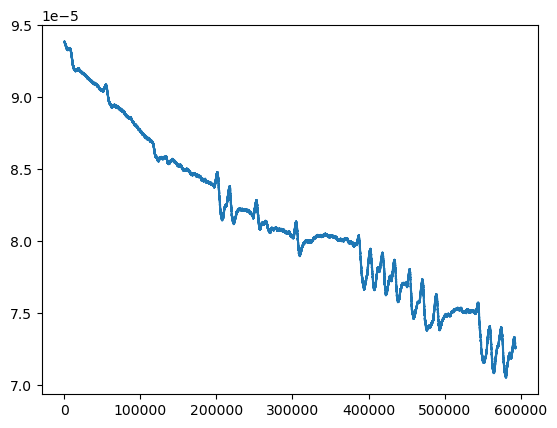

In [59]:
plt.plot(ns,ps)

In [31]:
counts_f, counts_Pxx=PSD.PSDanalysis(counts,counts,3433.869413,nperseg=int(1e4))

0


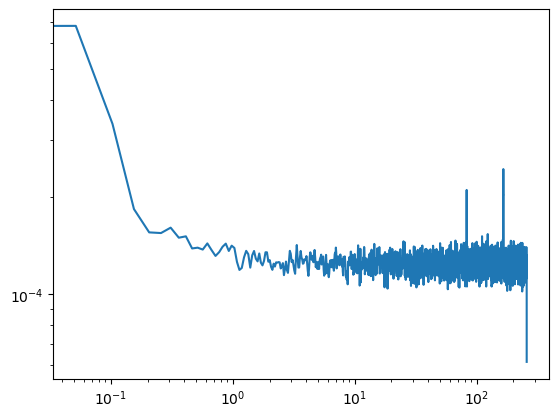

In [43]:
plt.loglog(counts_f, counts_Pxx)

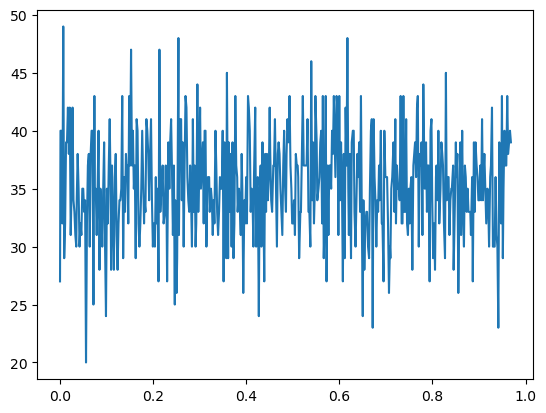

In [85]:
plt.plot(ts1[:500],counts[:500])

In [131]:
ts1[len(ts1)-1]

3433.869413

In [35]:
len(ts1)

NameError: name 'ts1' is not defined

In [119]:
tstest=[]
for i in range(len(ts1)-1):
    tstest.append(ts1[i+1]-ts1[i])

In [143]:
ts2=parse_vtd_seconds(meas_arr2[11][1])




In [145]:
ts2[len(ts2)-1]

693.01416

In [121]:
np.mean(tstest)

0.001941920795007592

In [37]:
meas_arr2 = import_all_measurements_as_array(r'D:\PhD Thesis Writing\Data\2025-07-24')


In [39]:
counts2_f, counts2_pxx=PSD.PSDanalysis(meas_arr2[11][3],meas_arr2[11][3],693.01416, nperseg=int(1e4))

0


In [47]:
ts3=parse_vtd_seconds(meas_arr2[12][1])
print(ts3[len(ts3)-1])

347.971506


In [49]:
counts3_f, counts3_pxx=PSD.PSDanalysis(meas_arr2[12][3],meas_arr2[12][3],347.971506, nperseg=int(1e4))

0


In [53]:
ts4=parse_vtd_seconds(meas_arr2[13][1])
print(ts4[len(ts4)-1])

541.093198


In [57]:
counts4_f, counts4_pxx=PSD.PSDanalysis(meas_arr2[13][3],meas_arr2[13][3],541.093198, nperseg=int(1e4))

0


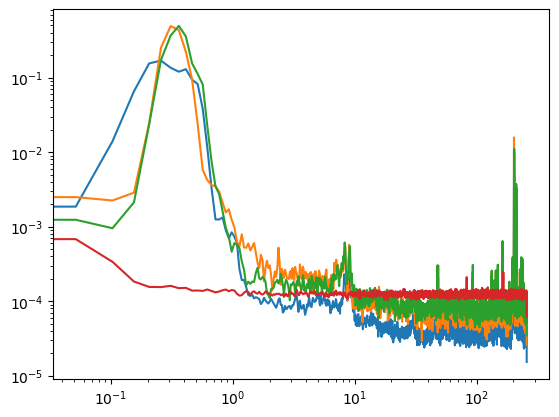

In [59]:
plt.loglog(counts2_f, counts2_pxx)
plt.loglog(counts3_f, counts3_pxx)
plt.loglog(counts4_f, counts4_pxx)
plt.loglog(counts_f, counts_Pxx)